# Problema 4: Árvore de Decisão (Risco de Crédito)

Classificação de risco de crédito no dataset German Credit (1.000 clientes, 20 atributos):
- `Risk`: Variável alvo (0 = Bom pagador, 1 = Mau pagador / Inadimplente)
- Foco: Regras de decisão interpretáveis e controle da complexidade da árvore (profundidade máxima) para evitar overfitting.
- Atributos principais: duração do empréstimo (meses), valor do crédito (DM), histórico de pagamentos, saldo em conta corrente e poupança, idade.


### 1. Importação das Bibliotecas

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

os.makedirs('graficos', exist_ok=True)


### 2. Tarefa 1: Identificação de Atributos e Codificação

In [2]:
dados = pd.read_csv('dataset/german_credit.csv')

num_cols = dados.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = dados.select_dtypes(include=['object', 'str']).columns.drop('class').tolist()

print(f"Atributos Numéricos ({len(num_cols)}): {num_cols}")
print(f"Atributos Categóricos ({len(cat_cols)}): {cat_cols}")

dist = dados['class'].value_counts()
print(f"\nDistribuição de Classes: Bons = {dist['good']} (70%), Maus = {dist['bad']} (30%)")


Atributos Numéricos (7): ['duration', 'credit_amount', 'installment_commitment', 'residence_since', 'age', 'existing_credits', 'num_dependents']
Atributos Categóricos (13): ['checking_status', 'credit_history', 'purpose', 'savings_status', 'employment', 'personal_status', 'other_parties', 'property_magnitude', 'other_payment_plans', 'housing', 'job', 'own_telephone', 'foreign_worker']

Distribuição de Classes: Bons = 700 (70%), Maus = 300 (30%)


#### O Paradoxo da Acurácia no Conjunto Desbalanceado (70% / 30%)
Um modelo simplório que previsse cegamente "bom pagador" para 100% dos clientes teria uma acurácia aparente de **70%**, mas aprovaria 100% dos inadimplentes, causando graves perdas financeiras à instituição. Portanto, a acurácia isolada é enganosa.


In [3]:
# Codificação via One-Hot Encoding para não criar ordens artificiais inexistentes
X = dados.drop(columns=['class'])
y = dados['class'].map({'good': 0, 'bad': 1}) # 0: bom pagador, 1: mau pagador
X_encoded = pd.get_dummies(X, drop_first=True)
print(f"Número total de colunas após One-Hot Encoding: {X_encoded.shape[1]}")


Número total de colunas após One-Hot Encoding: 48


### 3. Tarefas 2 e 3: Por que a normalização é dispensável? Divisão Treino/Teste
Árvores de decisão utilizam divisões por desigualdade ($x_j \le c$) que dependem exclusivamente da **ordem relativa** dos dados, e não da escala de magnitude. Como transformações monotônicas preservam a ordenação, a normalização não altera a estrutura dos nós.


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.20, random_state=42, stratify=y
)
print(f"Amostras de Treino: {len(X_train)} | Teste: {len(X_test)}")


Amostras de Treino: 800 | Teste: 200


### 4. Tarefa 4: Treinamento e Controle de Complexidade (Profundidade e Critério)
Treinamos com profundidades máximas [2, 3, 5, 7, 10, None] para **Gini** e **Entropia** com 5-fold CV.


In [5]:
profundidades = [2, 3, 5, 7, 10, None]
rotulos_prof = ['2', '3', '5', '7', '10', 'Sem Limite']
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

res_gini = {'treino': [], 'validacao': []}
res_entr = {'treino': [], 'validacao': []}

for max_d in profundidades:
    arv_g = DecisionTreeClassifier(criterion='gini', max_depth=max_d, random_state=42)
    s_g = cross_validate(arv_g, X_train, y_train, cv=cv, scoring='accuracy', return_train_score=True)
    res_gini['treino'].append(s_g['train_score'].mean())
    res_gini['validacao'].append(s_g['test_score'].mean())
    
    arv_e = DecisionTreeClassifier(criterion='entropy', max_depth=max_d, random_state=42)
    s_e = cross_validate(arv_e, X_train, y_train, cv=cv, scoring='accuracy', return_train_score=True)
    res_entr['treino'].append(s_e['train_score'].mean())
    res_entr['validacao'].append(s_e['test_score'].mean())

df_resumo = pd.DataFrame({
    'Profundidade': rotulos_prof,
    'Gini Treino': res_gini['treino'],
    'Gini Validação': res_gini['validacao'],
    'Entropia Treino': res_entr['treino'],
    'Entropia Validação': res_entr['validacao']
})
df_resumo.round(4)


,Profundidade,Gini Treino,Gini Validação,Entropia Treino,Entropia Validação
0,2,0.7081,0.6888,0.7069,0.6938
1,3,0.7369,0.6975,0.7322,0.6988
2,5,0.7953,0.7012,0.7853,0.7137
3,7,0.8600,0.6900,0.8447,0.7000
4,10,0.9328,0.6662,0.9109,0.7088
5,Sem Limite,1.0000,0.6650,1.0000,0.7088


#### Gráfico: Curva de Complexidade (Underfitting vs. Overfitting)
Observamos a divergência entre a acurácia de treino e validação conforme a profundidade cresce.


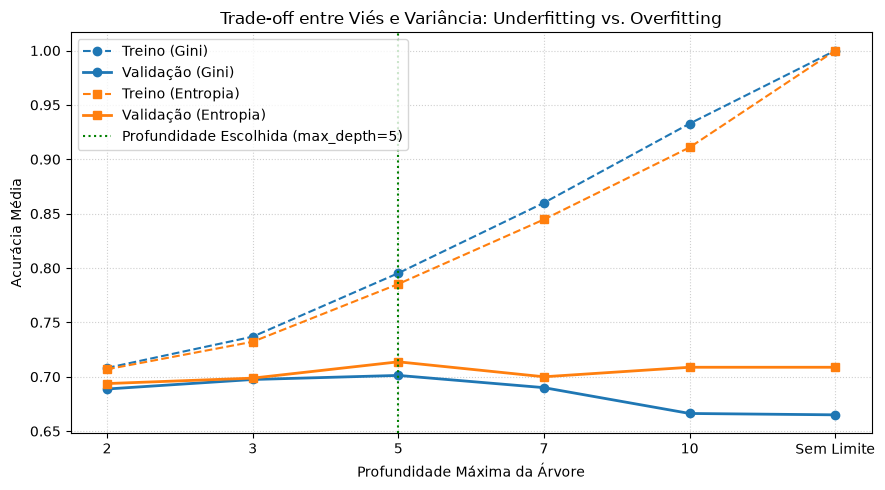

In [6]:
x_pos = np.arange(len(rotulos_prof))
plt.figure(figsize=(9, 5))
plt.plot(x_pos, res_gini['treino'], 'o--', color='#1f77b4', label='Treino (Gini)')
plt.plot(x_pos, res_gini['validacao'], 'o-', color='#1f77b4', lw=2, label='Validação (Gini)')
plt.plot(x_pos, res_entr['treino'], 's--', color='#ff7f0e', label='Treino (Entropia)')
plt.plot(x_pos, res_entr['validacao'], 's-', color='#ff7f0e', lw=2, label='Validação (Entropia)')
plt.xticks(x_pos, rotulos_prof)
plt.axvline(2, color='green', linestyle=':', label='Profundidade Escolhida (max_depth=5)')
plt.xlabel('Profundidade Máxima da Árvore')
plt.ylabel('Acurácia Média')
plt.title('Trade-off entre Viés e Variância: Underfitting vs. Overfitting')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.savefig('graficos/complexidade_profundidade.png', dpi=300)
plt.show()


### 5. Tarefa 5: Interpretação do Modelo e Importância dos Atributos
Avaliamos a importância das variáveis na árvore escolhida (`max_depth=5`).


In [7]:
prof_escolhida = 5
arvore_final = DecisionTreeClassifier(criterion='gini', max_depth=prof_escolhida, random_state=42)
arvore_final.fit(X_train, y_train)

importancias = pd.Series(arvore_final.feature_importances_, index=X_encoded.columns).sort_values(ascending=False)
print("Top 3 atributos mais determinantes:")
for i, (k, v) in enumerate(importancias.head(3).items(), 1):
    print(f"{i}. {k}: {v:.4f} ({v*100:.1f}% de importância)")


Top 3 atributos mais determinantes:
1. checking_status_A14: 0.2954 (29.5% de importância)
2. credit_amount: 0.2178 (21.8% de importância)
3. duration: 0.0853 (8.5% de importância)


#### Gráfico: Estrutura Visual da Árvore de Decisão
Plotamos a árvore para visualização das regras de divisão.


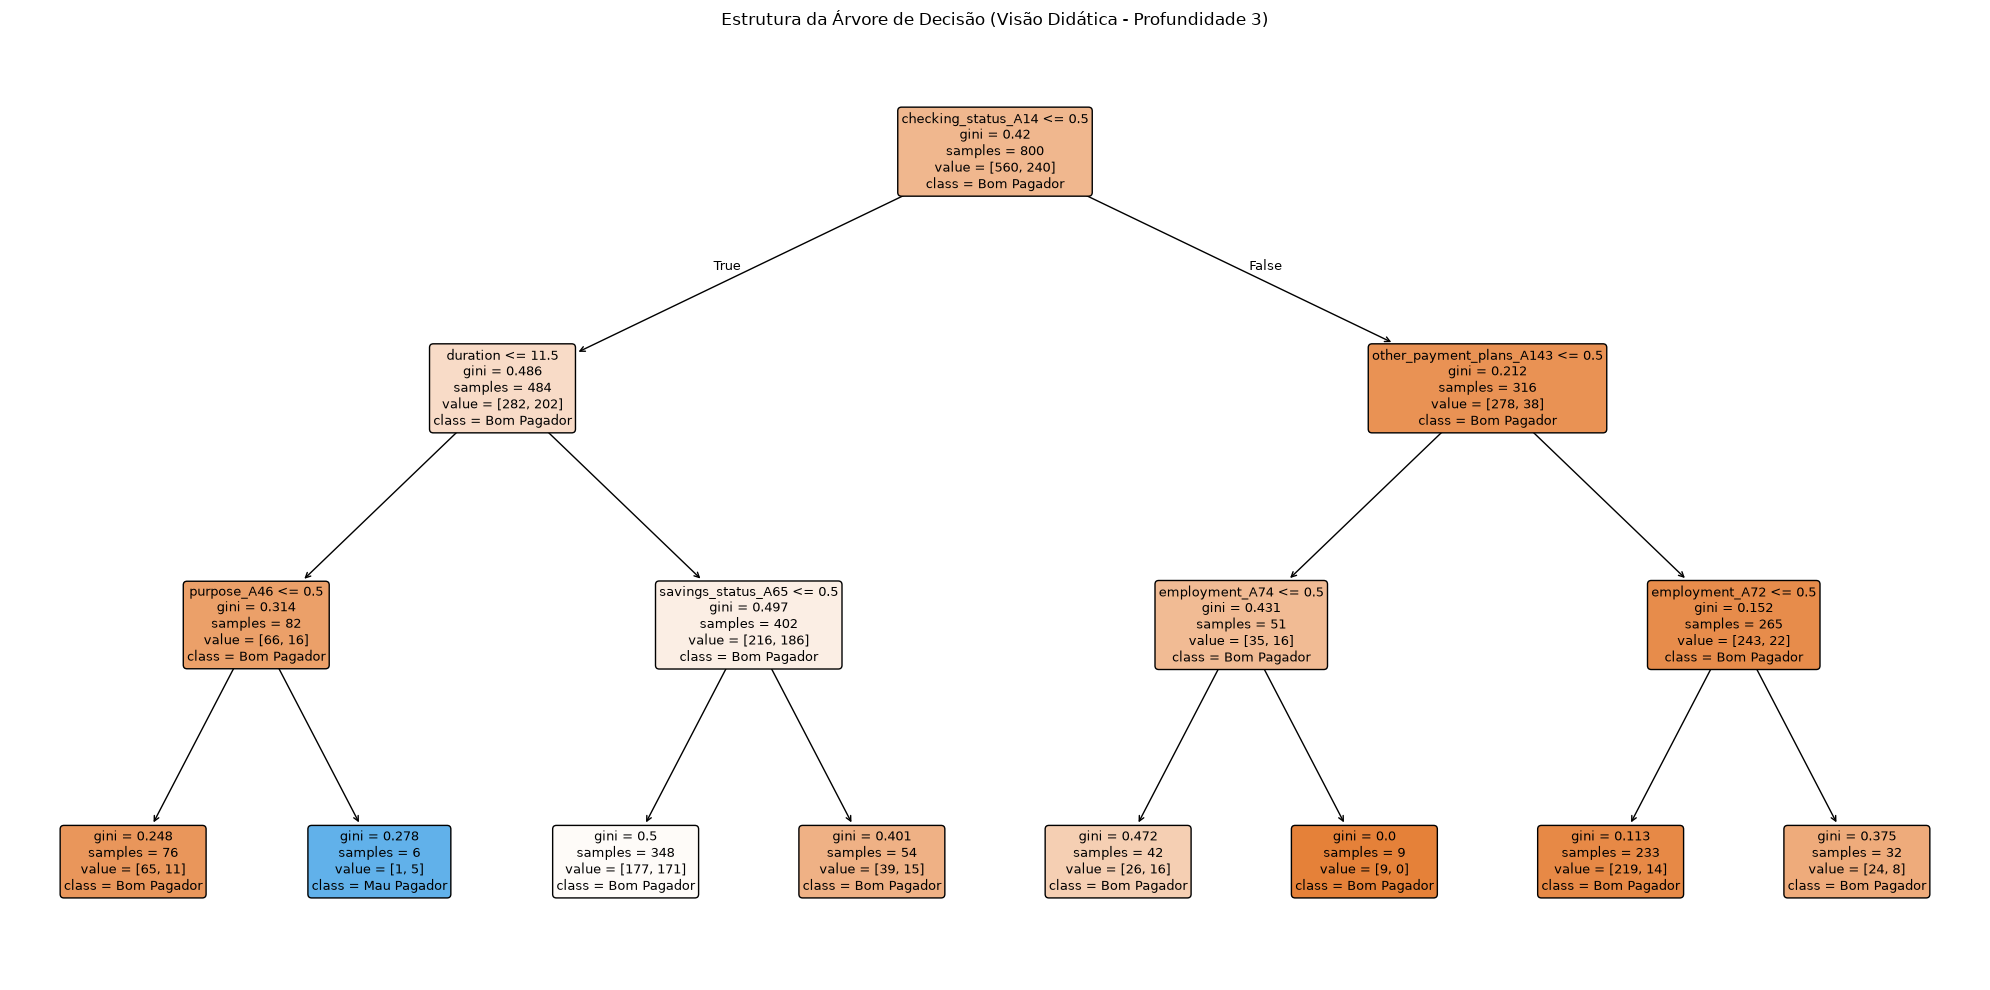

In [8]:
plt.figure(figsize=(20, 10))
arvore_plot = DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=42)
arvore_plot.fit(X_train, y_train)
plot_tree(arvore_plot, feature_names=list(X_encoded.columns),
          class_names=['Bom Pagador', 'Mau Pagador'], filled=True, rounded=True, fontsize=9)
plt.title('Estrutura da Árvore de Decisão (Visão Didática - Profundidade 3)')
plt.tight_layout()
plt.savefig('graficos/arvore_decisao.png', dpi=300)
plt.show()


#### Regra da Folha com Maior Mau Risco (Folha 19):
> **SE** o cliente possui conta corrente ativa sem saldo expressivo (`checking_status_A14 <= 0.50`)  
> **E** o empréstimo dura mais de 11.5 meses (`duration > 11.50`)  
> **E** a poupança não possui reserva elevada (`savings_status_A65 <= 0.50`)  
> **E** o valor do crédito solicitado for elevado (`credit_amount > 8015.50`)  
> **ENTÃO** classifique como **MAU PAGADOR** (nesta folha, a taxa de inadimplência real foi de **88.0%**).


### 6. Tarefa 6: Avaliação no Teste e Proposta de Ajuste
Avaliamos a matriz de confusão e testamos o balanceamento com `class_weight='balanced'`.


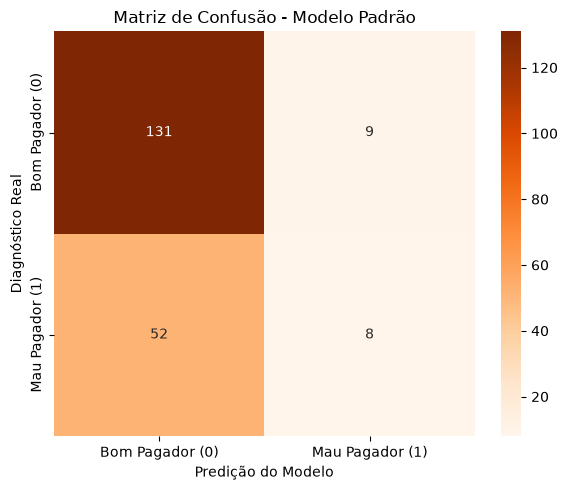

In [9]:
y_pred = arvore_final.predict(X_test)
matriz = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(matriz, annot=True, fmt='d', cmap='Oranges',
            xticklabels=['Bom Pagador (0)', 'Mau Pagador (1)'],
            yticklabels=['Bom Pagador (0)', 'Mau Pagador (1)'])
plt.xlabel('Predição do Modelo')
plt.ylabel('Diagnóstico Real')
plt.title('Matriz de Confusão - Modelo Padrão')
plt.tight_layout()
plt.savefig('graficos/matriz_confusao.png', dpi=300)
plt.show()


#### Ajuste no Treinamento com `class_weight='balanced'`
No setor de crédito, emprestar a um inadimplente (perda do principal) é muito mais grave do que recusar um bom cliente.


In [10]:
arvore_ajustada = DecisionTreeClassifier(criterion='gini', max_depth=prof_escolhida, random_state=42, class_weight='balanced')
arvore_ajustada.fit(X_train, y_train)

y_pred_ajustado = arvore_ajustada.predict(X_test)
matriz_ajustada = confusion_matrix(y_test, y_pred_ajustado)

print("Matriz de Confusão após Balanceamento:")
print(pd.DataFrame(matriz_ajustada, index=['Real: Bom', 'Real: Mau'], columns=['Prev: Bom', 'Prev: Mau']))
print(f"\nMaus pagadores erroneamente aprovados caíram de {matriz[1, 0]} para {matriz_ajustada[1, 0]}!")


Matriz de Confusão após Balanceamento:
           Prev: Bom  Prev: Mau
Real: Bom         83         57
Real: Mau         17         43

Maus pagadores erroneamente aprovados caíram de 52 para 17!
